# 28 · Forecasting a token's new buyers (work package 17)

**Work package 17** of the [applications plan](../../research/implementation_plan_applications.md), section 17.
At each evaluation point, for every token traded in the 14 days before: how many accounts pick it up for the first
time in the next 48 hours? Buyer counts drive volume and fees, which matter to liquidity providers and token teams.
The question is whether the recommender adds to what anyone can see without it.

- **Target:** $N_i$, accounts with a history before $t$ whose first trade of the token falls in the 48 hours after
  $t$. The count including brand-new accounts is reported alongside.
- **Baseline model (a):** linear regression of $\log(1 + N_i)$ on $\log(1 + \cdot)$ of new buyers in the 48 hours
  before $t$ (persistence), accounts in the last 24 hours, and token age.
- **Model (b):** the same plus $\log(1 + L_i)$, the number of accounts with the token in their top-50 list under
  the frozen fixed blend.
- Both are fitted on the 10 Dev A points; Dev B (11 points) and test (14 points) are scored.

**Criterion (stated in the plan):** on the test points, model (b) has a lower mean absolute error in
$\log(1 + N_i)$ than model (a): mean paired difference over points negative, 95% bootstrap interval excluding zero.
The tables were built by `src/scripts/build_demand_forecast.py` (results/wp17/).

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import demand_forecast as dfc
import plots
import protocol as pc
import stats

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
tokens = dfc.add_logs(pd.read_parquet(pc.RESULTS_DIR / "wp17" / "tokens.parquet"))
tokens.groupby("part").agg(
    points=("point", "nunique"), tokens_per_point=("token", lambda s: len(s) / tokens.loc[s.index, "point"].nunique()),
    share_with_new_buyers=("n_known", lambda n: (n > 0).mean()), mean_new_buyers=("n_known", "mean"),
    max_new_buyers=("n_known", "max"),
).loc[["dev_a", "dev_b", "test"]]  # fmt: skip

,points,tokens_per_point,share_with_new_buyers,mean_new_buyers,max_new_buyers
part,,,,,
dev_a,10,"20,255.200",0.127,0.695,3137
dev_b,11,"18,003.727",0.142,0.758,1307
test,14,"22,099.786",0.131,0.773,904


## 1. How the features relate to the target

Spearman correlation of each feature with $N_i$, pooled over the Dev A tokens.

In [2]:
dev_a = tokens[tokens["part"] == "dev_a"]
dev_a[["persistence", "users_24h", "age_days", "list_count"]].corrwith(dev_a["n_known"], method="spearman").rename("spearman with n_known")

persistence   0.477
users_24h     0.469
age_days      0.320
list_count    0.407
Name: spearman with n_known, dtype: float64

## 2. The two models, fitted on Dev A

In [3]:
from sklearn.linear_model import LinearRegression

for name, features in [("(a) baseline", dfc.BASELINE_FEATURES), ("(b) with lists", dfc.WITH_LISTS)]:
    fit = LinearRegression().fit(dev_a[features], dev_a["log_n_known"])
    print(f"{name}: intercept {fit.intercept_:+.3f}, " + ", ".join(f"{f} {c:+.3f}" for f, c in zip(features, fit.coef_)))

(a) baseline: intercept -0.252, log_persistence +0.231, log_users_24h +0.305, log_age_days +0.106
(b) with lists: intercept -0.241, log_persistence +0.185, log_users_24h +0.283, log_age_days +0.082, log_list_count +0.041


## 3. Dev B and test: does the list count lower the error?

Per point: the mean absolute error in $\log(1 + N_i)$ over all active tokens. `stats.compare` gives the paired
difference (b) − (a); a **negative** difference means the lists help.

In [4]:
def scores(part: str, target: str = "log_n_known") -> dict[str, pd.DataFrame]:
    """Per-point errors of both models (fitted on Dev A) on one part."""
    test = tokens[tokens["part"] == part]
    return {name: dfc.fit_and_score(dev_a, test, features, target) for name, features in
            [("(a) baseline", dfc.BASELINE_FEATURES), ("(b) with lists", dfc.WITH_LISTS)]}  # fmt: skip


results = {part: scores(part) for part in ("dev_b", "test")}
pd.concat({part: stats.compare(r, baseline="(a) baseline", metric="mae") for part, r in results.items()}, names=["part"]).droplevel(1)

,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
part,,,,,,,,,,
dev_b,(a) baseline,11,0.226,0.191,0.245,NaN,NaN,NaN,NaN,NaN
dev_b,(b) with lists,11,0.219,0.192,0.240,-0.007,-0.009,-0.004,1 of 11,0.012
test,(a) baseline,14,0.253,0.223,0.282,NaN,NaN,NaN,NaN,NaN
test,(b) with lists,14,0.234,0.198,0.266,-0.019,-0.022,-0.016,0 of 14,0.000


In [5]:
row = stats.compare(results["test"], baseline="(a) baseline", metric="mae").set_index("model").loc["(b) with lists"]
met = row["mean_difference"] < 0 and row["interval_high"] < 0
print(f"Test: (b) - (a) mean absolute error {row['mean_difference']:+.4f} [{row['interval_low']:+.4f}, {row['interval_high']:+.4f}], "
      f"(b) worse at {row['wins']} points -> criterion {'MET' if met else 'NOT met'}")  # fmt: skip

Test: (b) - (a) mean absolute error -0.0188 [-0.0219, -0.0160], (b) worse at 0 of 14 points -> criterion MET


In `stats.compare`, "wins" counts points where the metric is *higher*; for an error, those are the points where
(b) is worse.

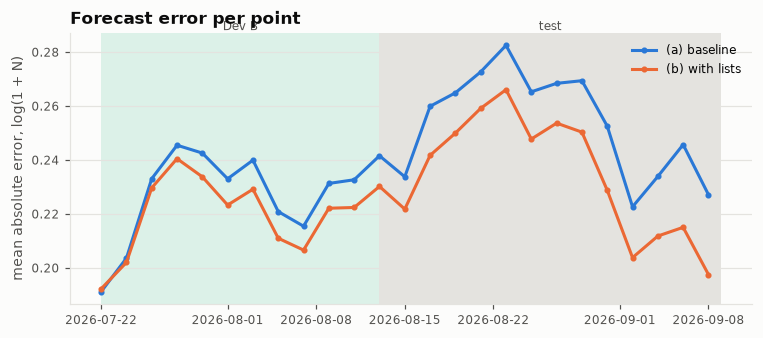

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for slot, name in enumerate(["(a) baseline", "(b) with lists"]):
    series = pd.concat([results[p][name] for p in ("dev_b", "test")]).sort_values("point")
    ax.plot(series["point"], series["mae"], marker="o", markersize=3, color=plots.SERIES[slot], label=name)
plots.shade_periods(ax, {"Dev B": (pc.DEV_B_START, pc.TEST_START), "test": (pc.TEST_START, tokens["point"].max() + pd.Timedelta(days=1))})
ax.set_ylabel("mean absolute error, log(1 + N)")
ax.set_title("Forecast error per point")
ax.legend()
plt.show()

## 4. Ranking, tail tokens, and tokens that do get buyers

Spearman correlation per point between forecast and outcome, the error on tokens outside the popular head, and
(since most active tokens get no new buyer at all) the error on the tokens with at least one.

In [7]:
def summary(part: str) -> pd.DataFrame:
    """Mean over points of Spearman, tail error and error on tokens with buyers, per model."""
    test = tokens[tokens["part"] == part]
    rows = {}
    for name, features in [("(a) baseline", dfc.BASELINE_FEATURES), ("(b) with lists", dfc.WITH_LISTS)]:
        per_point = dfc.fit_and_score(dev_a, test, features)
        with_buyers = dfc.fit_and_score(dev_a, test[test["n_known"] > 0], features)
        rows[name] = {"spearman": per_point["spearman"].mean(), "mae_tail": per_point["mae_tail"].mean(),
                      "mae_tokens_with_buyers": with_buyers["mae"].mean()}  # fmt: skip
    return pd.DataFrame(rows).T


pd.concat({part: summary(part) for part in ("dev_b", "test")}, names=["part"])

spearman  mae_tail  mae_tokens_with_buyers
part                                                            
dev_b (a) baseline       0.445     0.223                   0.595
      (b) with lists     0.451     0.217                   0.587
test  (a) baseline       0.422     0.250                   0.573
      (b) with lists     0.435     0.231                   0.574

## 5. Counting brand-new accounts too

The same comparison with the target $N^{all}_i$ (brand-new accounts included), models refitted on Dev A for it.
The recommender cannot see brand-new accounts, so its lists can only help through the buyers it knows.

In [8]:
pd.concat({part: stats.compare(scores(part, "log_n_all"), baseline="(a) baseline", metric="mae") for part in ("dev_b", "test")}, names=["part"]).droplevel(1)

,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
part,,,,,,,,,,
dev_b,(a) baseline,11,0.294,0.250,0.318,NaN,NaN,NaN,NaN,NaN
dev_b,(b) with lists,11,0.283,0.246,0.314,-0.010,-0.013,-0.008,0 of 11,0.001
test,(a) baseline,14,0.333,0.299,0.358,NaN,NaN,NaN,NaN,NaN
test,(b) with lists,14,0.310,0.277,0.338,-0.023,-0.027,-0.019,0 of 14,0.000


## 6. Forecast against outcome on test

Model (b)'s forecast of $\log(1 + N_i)$ against the outcome, for all test tokens (darker where more tokens fall).

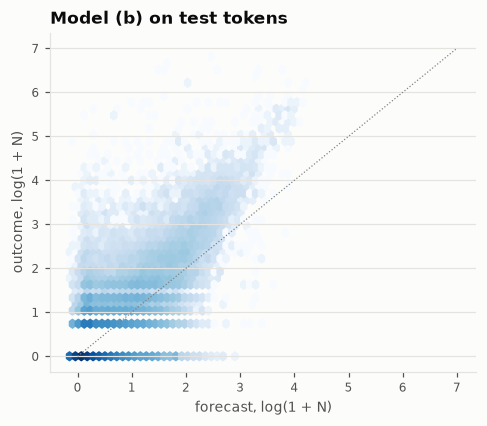

In [9]:
fit = LinearRegression().fit(dev_a[dfc.WITH_LISTS], dev_a["log_n_known"])
test = tokens[tokens["part"] == "test"]
fig, ax = plt.subplots(figsize=(5, 4))
ax.hexbin(fit.predict(test[dfc.WITH_LISTS]), test["log_n_known"], gridsize=40, bins="log", cmap="Blues")
ax.plot([0, 7], [0, 7], color="grey", linestyle=":", linewidth=0.8)
ax.set_xlabel("forecast, log(1 + N)")
ax.set_ylabel("outcome, log(1 + N)")
ax.set_title("Model (b) on test tokens")
plt.show()

## 7. What this shows

- **The criterion is met, but the gain is small.** Adding the list count lowers the test error from 0.253 to 0.234
  in $\log(1 + N)$ (−0.019, interval −0.022 to −0.016), at all 14 test points; on Dev B the gain is smaller
  (−0.007, better at 10 of 11 points). That is a 3-7% lower error.
- **The gain is in telling dead tokens from live ones, not in sizing demand.** Only 13-14% of active tokens get
  any new buyer in 48 hours. On the tokens that do, the two models are equally good (0.573 and 0.574 on test), and
  the rank correlation with the outcome rises only from 0.42 to 0.44.
- **Why so little:** what anyone can see (new buyers in the last 48 hours, accounts in the last 24 hours) already
  carries most of what the lists know. On its own, the list count is about as correlated with the outcome
  (Spearman 0.41) as the public features (0.47 and 0.47), and in the regression its coefficient is small (+0.04).
- **With brand-new accounts counted** the gain is similar (−0.023 on test, 0 of 14 points worse).
- **What it means:** the recommender's demand signal is real and consistently adds information, but a token's
  recent buyer flow already predicts most of its next 48 hours. As a product, it would mainly help screen out
  tokens that are about to stop attracting buyers; it does not forecast the size of demand better than recent flow.